# Heart Disease Prediction — End-to-End Machine Learning

This notebook explores a heart disease classification dataset, performs data cleaning and preprocessing, compares machine learning models using stratified cross-validation, evaluates the selected model on a held-out test set, and saves model artifacts.

> **Disclaimer:** This is an educational machine-learning project using a synthetic dataset. It is not intended for clinical diagnosis or medical decision-making.

**Dataset file expected:** `heart_disease_raw_practice.csv` in the same directory as this notebook.


In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [2]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay)
from sklearn.ensemble import VotingClassifier, StackingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

In [3]:

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.ensemble import GradientBoostingClassifier

import joblib


In [4]:
RANDOM_STATE = 42
DATA_PATH = Path("heart_disease_raw_practice.csv")
ARTIFACT_DIR = Path("artifacts")
ARTIFACT_DIR.mkdir(exist_ok=True)

print("Imports complete.")

Imports complete.


In [5]:
df_raw = pd.read_csv(DATA_PATH)
print("Shape:", df_raw.shape)
display(df_raw.head())
display(df_raw.sample(5, random_state=RANDOM_STATE))
df_raw.info()

Shape: (600, 14)


,age,sex,chest_pain_type,resting_blood_pressure,cholesterol,fasting_blood_sugar_gt_120,resting_ecg,max_heart_rate,exercise_induced_angina,oldpeak,st_slope,num_major_vessels,thalassemia,heart_disease
0,57.0,1,4.0,145.0,232.0,1,0,132.0,0,0.5,2,1,7.0,1
1,45.0,1,3.0,133.0,287.0,0,0,135.0,1,3.2,2,0,3.0,0
2,61.0,0,3.0,90.0,166.0,0,0,138.0,0,1.0,1,3,3.0,1
3,62.0,1,4.0,114.0,219.0,0,0,158.0,0,NaN,2,0,3.0,1
4,36.0,1,1.0,143.0,NaN,0,0,179.0,0,0.4,3,0,3.0,0


,age,sex,chest_pain_type,resting_blood_pressure,cholesterol,fasting_blood_sugar_gt_120,resting_ecg,max_heart_rate,exercise_induced_angina,oldpeak,st_slope,num_major_vessels,thalassemia,heart_disease
110,58.0,1,4.0,148.0,288.0,1,2,169.0,0,0.5,2,0,3.0,0
419,66.0,0,2.0,117.0,213.0,1,0,157.0,0,3.8,1,2,3.0,0
565,61.0,1,4.0,115.0,258.0,0,0,156.0,1,0.8,1,1,7.0,1
77,55.0,0,4.0,149.0,215.0,0,0,176.0,0,1.9,2,0,7.0,0
181,56.0,1,4.0,120.0,248.0,0,1,163.0,0,2.4,3,1,3.0,1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 14 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   age                         585 non-null    float64
 1   sex                         600 non-null    int64  
 2   chest_pain_type             591 non-null    float64
 3   resting_blood_pressure      576 non-null    float64
 4   cholesterol                 558 non-null    float64
 5   fasting_blood_sugar_gt_120  600 non-null    int64  
 6   resting_ecg                 600 non-null    int64  
 7   max_heart_rate              582 non-null    float64
 8   exercise_induced_angina     600 non-null    int64  
 9   oldpeak                     576 non-null    float64
 10  st_slope                    600 non-null    int64  
 11  num_major_vessels           600 non-null    int64  
 12  thalassemia                 582 non-null    float64
 13  heart_disease               600 non

In [6]:
print("Duplicate rows:", df_raw.duplicated().sum())
missing = df_raw.isna().sum().sort_values(ascending=False)
display(missing[missing > 0].to_frame("missing_count"))
print("Target distribution:")
display(df_raw["heart_disease"].value_counts().rename_axis("heart_disease").to_frame("count"))
display((df_raw["heart_disease"].value_counts(normalize=True) * 100).round(1).rename("percent").to_frame())

Duplicate rows: 0


,missing_count
cholesterol,42
resting_blood_pressure,24
oldpeak,24
max_heart_rate,18
thalassemia,18
age,15
chest_pain_type,9


Target distribution:


,count
heart_disease,
1,308
0,292


,percent
heart_disease,
1,51.3
0,48.7


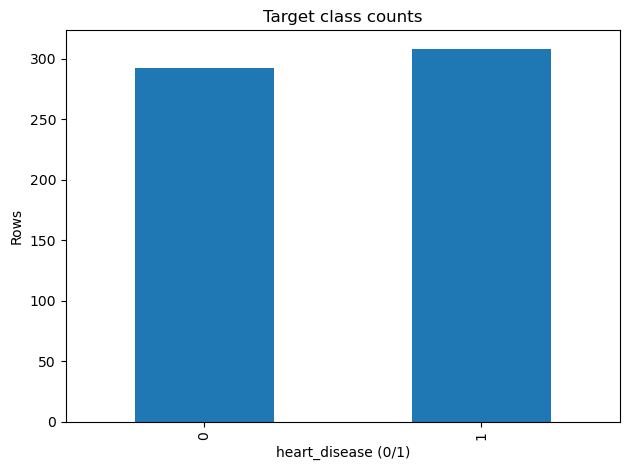

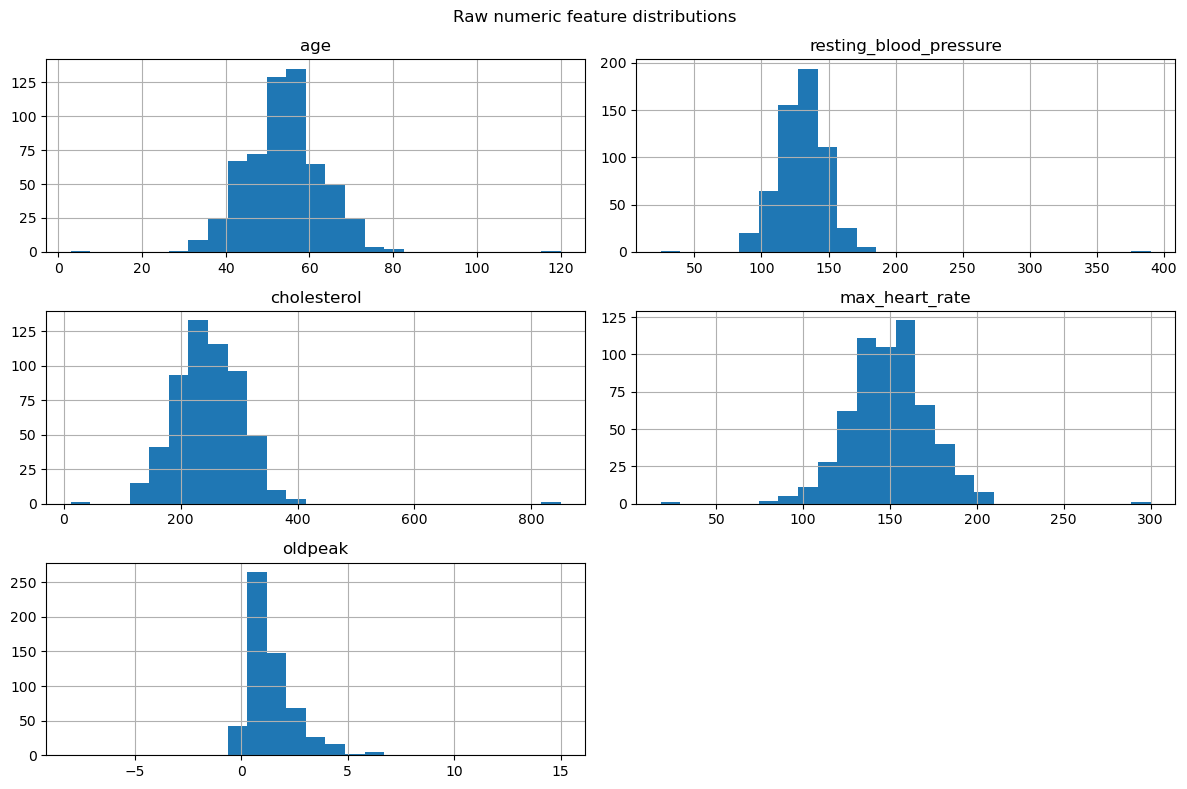

In [7]:
target_counts = df_raw["heart_disease"].value_counts().sort_index()
target_counts.plot(kind="bar", title="Target class counts", xlabel="heart_disease (0/1)", ylabel="Rows")
plt.tight_layout()
plt.show()

numeric_for_plot = [
    "age", "resting_blood_pressure", "cholesterol",
    "max_heart_rate", "oldpeak"
]
df_raw[numeric_for_plot].hist(figsize=(12, 8), bins=25)
plt.suptitle("Raw numeric feature distributions")
plt.tight_layout()
plt.show()

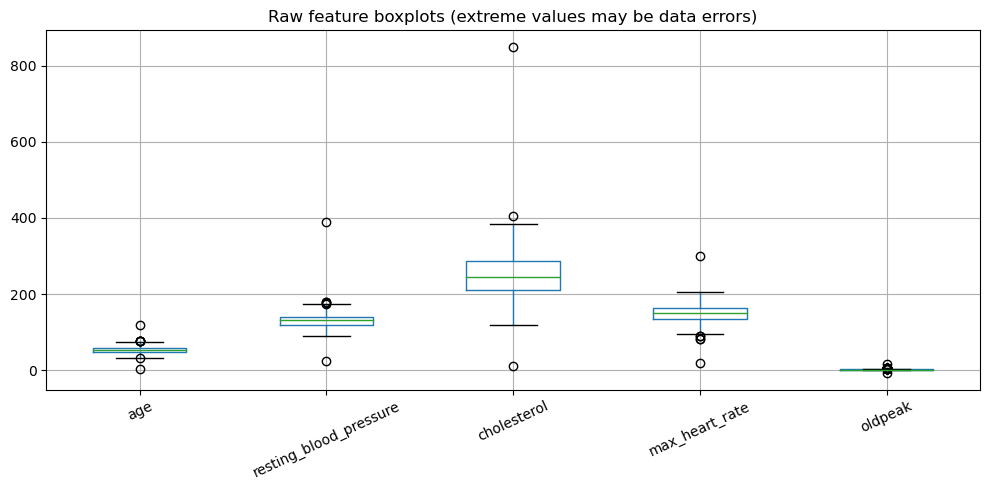

In [8]:
plt.figure(figsize=(10, 5))
df_raw[numeric_for_plot].boxplot(rot=25)
plt.title("Raw feature boxplots (extreme values may be data errors)")
plt.tight_layout()
plt.show()

In [9]:
df = df_raw.copy()

plausible_ranges = {
    "age": (18, 100),
    "resting_blood_pressure": (60, 260),
    "cholesterol": (50, 700),
    "max_heart_rate": (40, 230),
    "oldpeak": (0, 10),
}

quality_report = []
for col, (low, high) in plausible_ranges.items():
    bad_mask = df[col].notna() & ~df[col].between(low, high)
    quality_report.append({
        "column": col,
        "outside_range_count": int(bad_mask.sum()),
        "allowed_min_for_this_project": low,
        "allowed_max_for_this_project": high
    })
    df.loc[bad_mask, col] = np.nan

display(pd.DataFrame(quality_report))
print("Missing values after invalid-extreme treatment:")
display(df.isna().sum()[df.isna().sum() > 0].to_frame("missing_count"))

,column,outside_range_count,allowed_min_for_this_project,allowed_max_for_this_project
0,age,2,18,100
1,resting_blood_pressure,2,60,260
2,cholesterol,2,50,700
3,max_heart_rate,2,40,230
4,oldpeak,2,0,10


Missing values after invalid-extreme treatment:


,missing_count
age,17
chest_pain_type,9
resting_blood_pressure,26
cholesterol,44
max_heart_rate,20
oldpeak,26
thalassemia,18


In [10]:
iqr_rows = []
for col in numeric_for_plot:
    s = df[col].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    iqr_rows.append({
        "feature": col, "IQR_lower_fence": low, "IQR_upper_fence": high,
        "IQR_flagged_count": int(((s < low) | (s > high)).sum())
    })
display(pd.DataFrame(iqr_rows))

,feature,IQR_lower_fence,IQR_upper_fence,IQR_flagged_count
0,age,31.5,75.5,6
1,resting_blood_pressure,86.0,174.0,4
2,cholesterol,98.5,398.5,1
3,max_heart_rate,93.0,205.0,4
4,oldpeak,-1.5,4.1,20


In [11]:
target_col = "heart_disease"
categorical_cols = [
    "sex", "chest_pain_type", "fasting_blood_sugar_gt_120",
    "resting_ecg", "exercise_induced_angina", "st_slope",
    "num_major_vessels", "thalassemia"
]
numeric_cols = [
    "age", "resting_blood_pressure", "cholesterol",
    "max_heart_rate", "oldpeak"
]

X = df.drop(columns=target_col)
y = df[target_col].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train.shape, "Test:", X_test.shape)
print("Training target proportions:")
display(y_train.value_counts(normalize=True).sort_index().rename("proportion").to_frame())
print("Testing target proportions:")
display(y_test.value_counts(normalize=True).sort_index().rename("proportion").to_frame())

Train: (480, 13) Test: (120, 13)
Training target proportions:


,proportion
heart_disease,
0,0.4875
1,0.5125


Testing target proportions:


,proportion
heart_disease,
0,0.483333
1,0.516667


In [12]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numeric_cols),
    ("cat", categorical_pipeline, categorical_cols)
], remainder="drop")

print("Preprocessor defined. It will be fitted inside each model pipeline.")

Preprocessor defined. It will be fitted inside each model pipeline.


In [15]:

# Define 6 Machine Learning Algorithms

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=RANDOM_STATE
    ),

    "SVM": SVC(
        probability=True,
        random_state=RANDOM_STATE
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=RANDOM_STATE
    )
}

# 5-Fold Cross Validation

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

cv_rows = []

for name, estimator in models.items():

    pipe = Pipeline(steps=[
        ("preprocessing", preprocessor),
        ("model", estimator)
    ])

    scores = cross_validate(
        pipe,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring
    )

    cv_rows.append({
    "model": name,
    "cv_accuracy_mean": scores["test_accuracy"].mean(),
    "cv_precision_mean": scores["test_precision"].mean(),
    "cv_recall_mean": scores["test_recall"].mean(),
    "cv_f1_mean": scores["test_f1"].mean(),
    "cv_roc_auc_mean": scores["test_roc_auc"].mean()
})

cv_results = pd.DataFrame(cv_rows)

display(cv_results.round(3))


,model,cv_accuracy_mean,cv_precision_mean,cv_recall_mean,cv_f1_mean,cv_roc_auc_mean
0,Logistic Regression,0.642,0.658,0.630,0.643,0.713
1,KNN,0.575,0.582,0.614,0.596,0.612
2,Decision Tree,0.567,0.577,0.581,0.578,0.566
3,Random Forest,0.594,0.601,0.618,0.609,0.664
4,SVM,0.623,0.638,0.614,0.625,0.685
5,Gradient Boosting,0.602,0.608,0.634,0.620,0.637


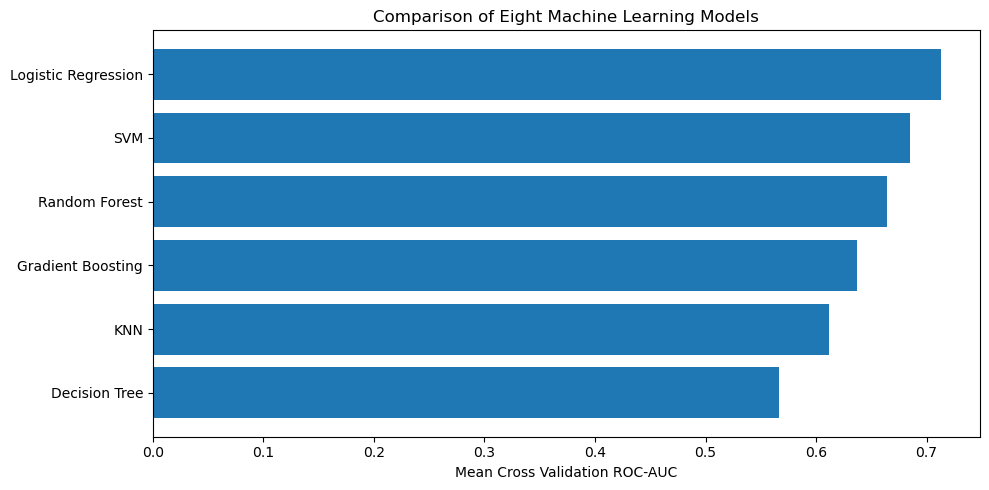

In [16]:
plot_df = cv_results.sort_values("cv_roc_auc_mean")

plt.figure(figsize=(10, 5))
plt.barh(plot_df["model"], plot_df["cv_roc_auc_mean"])
plt.xlabel("Mean Cross Validation ROC-AUC")
plt.title("Comparison of Eight Machine Learning Models")
plt.tight_layout()
plt.show()


In [17]:
voting = VotingClassifier(
    estimators=[
        ("lr", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE)),
        ("rf", RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1)),
        ("svc", SVC(probability=True, class_weight="balanced", random_state=RANDOM_STATE))
    ],
    voting="soft"
)

stacking = StackingClassifier(
    estimators=[
        ("lr", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE)),
        ("rf", RandomForestClassifier(n_estimators=150, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1)),
        ("gnb", GaussianNB())
    ],
    final_estimator=LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE),
    cv=3,
    n_jobs=-1
)

ensemble_rows = []
for name, estimator in {"Soft Voting Ensemble": voting, "Stacking Ensemble": stacking}.items():
    pipe = Pipeline([("preprocessing", preprocessor), ("model", estimator)])
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    ensemble_rows.append({
        "model": name,
        "cv_accuracy_mean": scores["test_accuracy"].mean(),
        "cv_accuracy_std": scores["test_accuracy"].std(),
        "cv_f1_mean": scores["test_f1"].mean(),
        "cv_recall_mean": scores["test_recall"].mean(),
        "cv_roc_auc_mean": scores["test_roc_auc"].mean()
    })

cv_results = pd.concat([cv_results, pd.DataFrame(ensemble_rows)], ignore_index=True)
cv_results = cv_results.sort_values("cv_roc_auc_mean", ascending=False).reset_index(drop=True)
display(cv_results.round(3))

,model,cv_accuracy_mean,cv_precision_mean,cv_recall_mean,cv_f1_mean,cv_roc_auc_mean,cv_accuracy_std
0,Logistic Regression,0.642,0.658,0.630,0.643,0.713,NaN
1,Stacking Ensemble,0.642,NaN,0.630,0.642,0.710,0.033
2,Soft Voting Ensemble,0.627,NaN,0.638,0.637,0.702,0.026
3,SVM,0.623,0.638,0.614,0.625,0.685,NaN
4,Random Forest,0.594,0.601,0.618,0.609,0.664,NaN
5,Gradient Boosting,0.602,0.608,0.634,0.620,0.637,NaN
6,KNN,0.575,0.582,0.614,0.596,0.612,NaN
7,Decision Tree,0.567,0.577,0.581,0.578,0.566,NaN


In [18]:
all_estimators = dict(models)
all_estimators.update({"Soft Voting Ensemble": voting, "Stacking Ensemble": stacking})

best_name = cv_results.iloc[0]["model"]
best_estimator = all_estimators[best_name]
best_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", best_estimator)
])
best_model.fit(X_train, y_train)

y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1] if hasattr(best_model, "predict_proba") else None

test_metrics = {
    "selected_model": best_name,
    "test_accuracy": float(accuracy_score(y_test, y_pred)),
    "test_precision": float(precision_score(y_test, y_pred, zero_division=0)),
    "test_recall": float(recall_score(y_test, y_pred, zero_division=0)),
    "test_f1": float(f1_score(y_test, y_pred, zero_division=0)),
    "test_roc_auc": float(roc_auc_score(y_test, y_prob)) if y_prob is not None else None
}
print(json.dumps(test_metrics, indent=2))
print(classification_report(y_test, y_pred, target_names=["No disease (0)", "Disease (1)"], zero_division=0))

{
  "selected_model": "Logistic Regression",
  "test_accuracy": 0.675,
  "test_precision": 0.7017543859649122,
  "test_recall": 0.6451612903225806,
  "test_f1": 0.6722689075630253,
  "test_roc_auc": 0.7241379310344828
}
                precision    recall  f1-score   support

No disease (0)       0.65      0.71      0.68        58
   Disease (1)       0.70      0.65      0.67        62

      accuracy                           0.68       120
     macro avg       0.68      0.68      0.67       120
  weighted avg       0.68      0.68      0.67       120



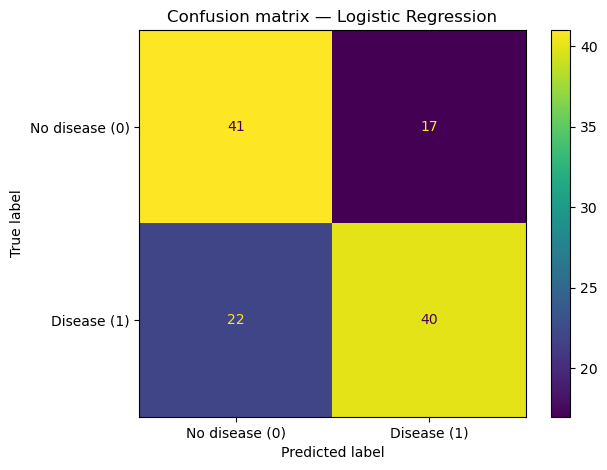

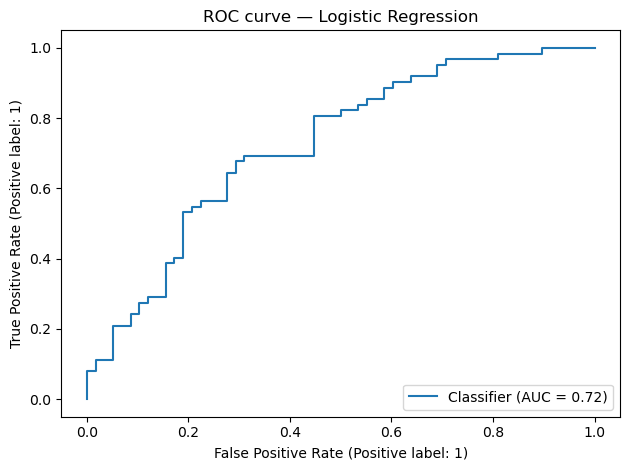

In [19]:
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["No disease (0)", "Disease (1)"], cmap=None
)
plt.title(f"Confusion matrix — {best_name}")
plt.tight_layout()
plt.show()

if y_prob is not None:
    RocCurveDisplay.from_predictions(y_test, y_prob)
    plt.title(f"ROC curve — {best_name}")
    plt.tight_layout()
    plt.show()

In [20]:
joblib.dump(best_model, ARTIFACT_DIR / "heart_disease_best_model.joblib")
cv_results.to_csv(ARTIFACT_DIR / "model_comparison.csv", index=False)
pd.DataFrame([test_metrics]).to_csv(ARTIFACT_DIR / "test_metrics.csv", index=False)

metadata = {
    "selected_model": best_name,
    "target": target_col,
    "feature_columns": X.columns.tolist(),
    "numeric_columns": numeric_cols,
    "categorical_columns": categorical_cols,
    "dataset_note": "Synthetic educational dataset. Not for clinical use."
}
(ARTIFACT_DIR / "model_metadata.json").write_text(json.dumps(metadata, indent=2))

print("Saved artifacts:")
for p in sorted(ARTIFACT_DIR.iterdir()):
    print("-", p)

Saved artifacts:
- artifacts\heart_disease_best_model.joblib
- artifacts\model_comparison.csv
- artifacts\model_metadata.json
- artifacts\test_metrics.csv


In [21]:
# Project files are expected in the repository root. No machine-specific paths are needed.

C:\Users\Varun Rayapati R\Downloads\heart_disease_end_to_end_project\heart_disease_end_to_end_project


In [22]:
# Project files are expected in the repository root. No machine-specific paths are needed.

['.ipynb_checkpoints', 'app.py', 'artifacts', 'Heart_Disease_End_to_End_ML.ipynb', 'heart_disease_raw_practice.csv', 'README.md', 'requirements.txt']


In [23]:
# Project files are expected in the repository root. No machine-specific paths are needed.

C:\Users\Varun Rayapati R\Downloads\heart_disease_end_to_end_project\heart_disease_end_to_end_project
['.ipynb_checkpoints', 'app.py', 'artifacts', 'Heart_Disease_End_to_End_ML.ipynb', 'heart_disease_raw_practice.csv', 'README.md', 'requirements.txt']
